---
                         Predicción de Demanda con Deep Learning — Superstore Sales

---

                                            Autor: Diego Yeferson Quispe Huamani

---





**Fuente de datos:** Kaggle — *"Superstore Sales Dataset"* (Rohit Sahoo)
🔗 https://www.kaggle.com/datasets/rohitsahoo/sales-forecasting
9,994 transacciones (~USD 2.3 millones en ventas), 2014–2017.

---

## ¿De qué trata este proyecto?

Superstore es una tienda retail de EE.UU. que vende Furniture, Office Supplies y Technology. El objetivo es **predecir la demanda mensual (ventas en USD)** para los próximos meses, de manera que el equipo comercial pueda anticipar compras a proveedores, planificar inventario y dimensionar campañas — sobre todo porque el negocio tiene una estacionalidad marcada (pico fuerte en noviembre-diciembre).



---


 **flujo de trabajo**


1. Cargar y preparar los datos a nivel mensual.
2. Explorar la serie (tickets, unidades, ventas) con medias móviles y bandas de tolerancia.
3. Revisar autocorrelación (ACF/PACF) y descomponer la serie en tendencia + estacionalidad + residuo.
4. Probar varios modelos de pronóstico: Naive, ARIMA, Auto-ARIMA, SARIMA, Prophet y un modelo de Deep Learning (LSTM).
5. Comparar todos los modelos con RMSE y MAPE, elegir el mejor, y generar el pronóstico de los próximos 12 meses.

## 1. Librerías



In [ ]:
%matplotlib inline
import os
import json
import warnings
warnings.filterwarnings("ignore")

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

import statsmodels.api as sm
from statsmodels.graphics.tsaplots import plot_acf, plot_pacf
from statsmodels.tsa.arima.model import ARIMA
from statsmodels.tsa.statespace.sarimax import SARIMAX
from pmdarima import auto_arima
from prophet import Prophet

import tensorflow as tf
from sklearn.preprocessing import MinMaxScaler
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import LSTM, Dense, Input

plt.rcParams["figure.dpi"] = 100
print("Librerías cargadas correctamente ✅")

Librerías cargadas correctamente ✅


## 2. Carga y preparación de los datos



In [ ]:
df = pd.read_csv("../data/raw/superstore_sales.csv", encoding="latin")
df.columns = [c.replace(" ", "") for c in df.columns]
df["OrderDate"] = pd.to_datetime(df["OrderDate"])

ts_df = df[["OrderID", "OrderDate", "Quantity", "Sales", "Category"]].copy().set_index("OrderDate")

monthly_unique_orders = ts_df["OrderID"].resample("MS").nunique()
monthly_quantities = ts_df["Quantity"].resample("MS").sum()
monthly_sales = ts_df["Sales"].resample("MS").sum()

print("Filas del dataset:", df.shape)
print("Meses de historia:", monthly_sales.shape[0])
print("Rango de fechas:", monthly_sales.index.min().date(), "->", monthly_sales.index.max().date())
df.head()

Filas del dataset: (9994, 21)
Meses de historia: 48
Rango de fechas: 2014-01-01 -> 2017-12-01


,RowID,OrderID,OrderDate,ShipDate,ShipMode,CustomerID,CustomerName,Segment,Country,City,...,PostalCode,Region,ProductID,Category,Sub-Category,ProductName,Sales,Quantity,Discount,Profit
0,1,US-2014-10000,2014-01-03,2014-01-08,Standard Class,CU-00686,Cliente 0686,Home Office,United States,New York City,...,72163,East,OFF-EN-000001,Office Supplies,Envelopes,Envelopes modelo 001,112.56,7,0.0,11.74
1,2,US-2014-10001,2014-01-03,2014-01-08,Standard Class,CU-00370,Cliente 0370,Corporate,United States,Chicago,...,48206,Central,FUR-FU-000002,Furniture,Furnishings,Furnishings modelo 002,219.22,2,0.1,51.54
2,3,US-2014-10001,2014-01-03,2014-01-08,Standard Class,CU-00370,Cliente 0370,Corporate,United States,Chicago,...,48206,Central,TEC-AC-000003,Technology,Accessories,Accessories modelo 003,104.76,1,0.0,8.70
3,4,US-2014-10001,2014-01-03,2014-01-08,Standard Class,CU-00370,Cliente 0370,Corporate,United States,Chicago,...,48206,Central,OFF-ST-000004,Office Supplies,Storage,Storage modelo 004,52.84,4,0.2,6.49
4,5,US-2014-10001,2014-01-03,2014-01-08,Standard Class,CU-00370,Cliente 0370,Corporate,United States,Chicago,...,48206,Central,TEC-MA-000005,Technology,Machines,Machines modelo 005,259.91,2,0.0,43.22


Tengo **48 meses de historia** (enero 2014 a diciembre 2017), que es justo lo mínimo razonable para poder ver 4 ciclos anuales completos y entrenar modelos estacionales. Con menos de eso ya sería difícil que un modelo aprenda el patrón de temporada alta de fin de año.

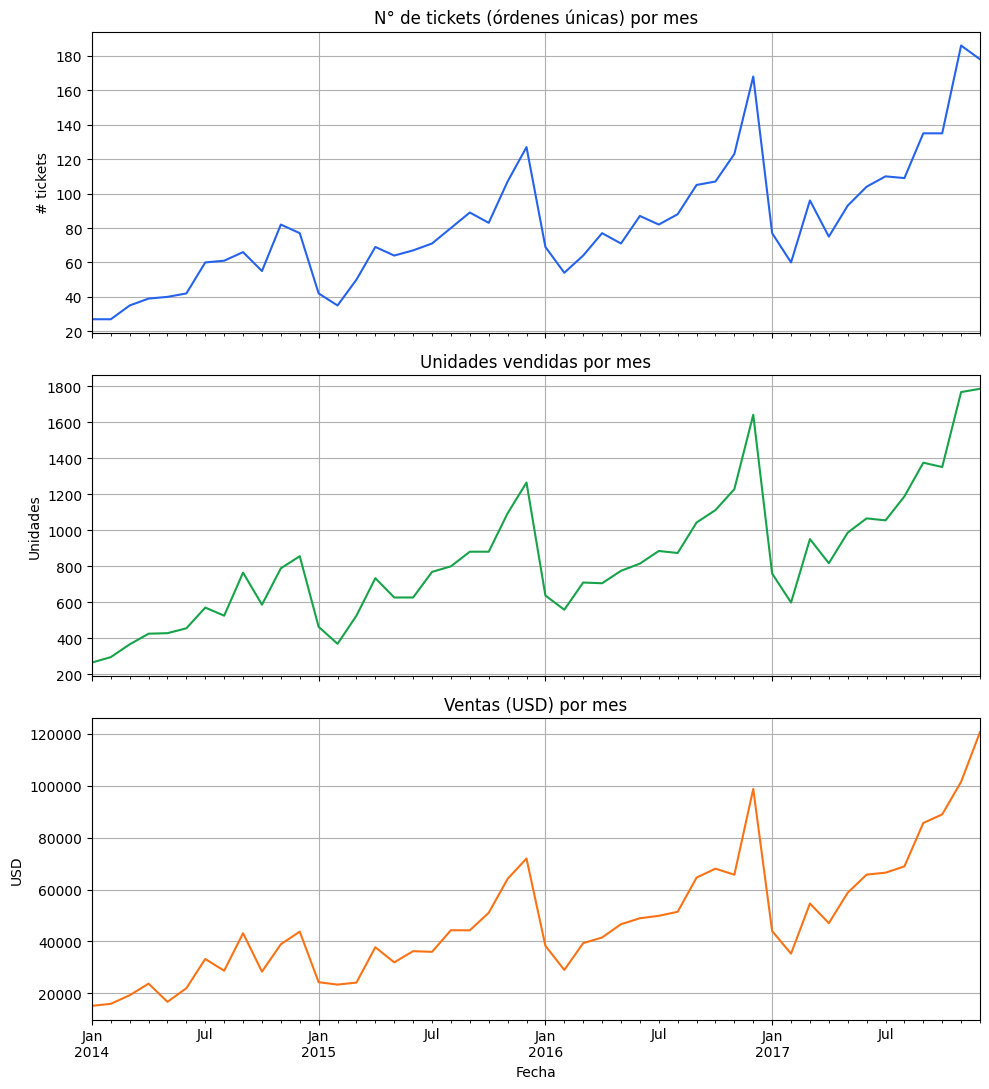

In [ ]:
monthly_unique_order_changes = (monthly_unique_orders - monthly_unique_orders.shift()) / monthly_unique_orders.shift() * 100
monthly_quantities_changes = (monthly_quantities - monthly_quantities.shift()) / monthly_quantities.shift() * 100
monthly_sales_changes = (monthly_sales - monthly_sales.shift()) / monthly_sales.shift() * 100

fig, axes = plt.subplots(nrows=3, ncols=1, figsize=(10, 11), sharex=True)
monthly_unique_orders.plot(ax=axes[0], grid=True, color="#2563eb")
axes[0].set_title("N° de tickets (órdenes únicas) por mes")
axes[0].set_ylabel("# tickets")
monthly_quantities.plot(ax=axes[1], grid=True, color="#16a34a")
axes[1].set_title("Unidades vendidas por mes")
axes[1].set_ylabel("Unidades")
monthly_sales.plot(ax=axes[2], grid=True, color="#f97316")
axes[2].set_title("Ventas (USD) por mes")
axes[2].set_ylabel("USD")
axes[2].set_xlabel("Fecha")
fig.tight_layout()
plt.show()

Las tres series se mueven prácticamente juntas (tiene sentido, más tickets → más unidades → más ventas) y las tres muestran el mismo patrón: una tendencia creciente de fondo (el negocio va vendiendo más año a año) con picos muy marcados hacia noviembre-diciembre, que es justo la temporada alta de retail (Black Friday, Navidad). Esto ya me anticipa que voy a necesitar un modelo que capture **tendencia + estacionalidad anual**, no solo un promedio simple.

## 3. Medias móviles (Moving Averages)

Calculo medias móviles de 6 y 12 meses para suavizar el ruido y ver mejor la tendencia de fondo. La de 12 meses, al cubrir un ciclo anual completo, debería verse bastante más suave que la de 6.

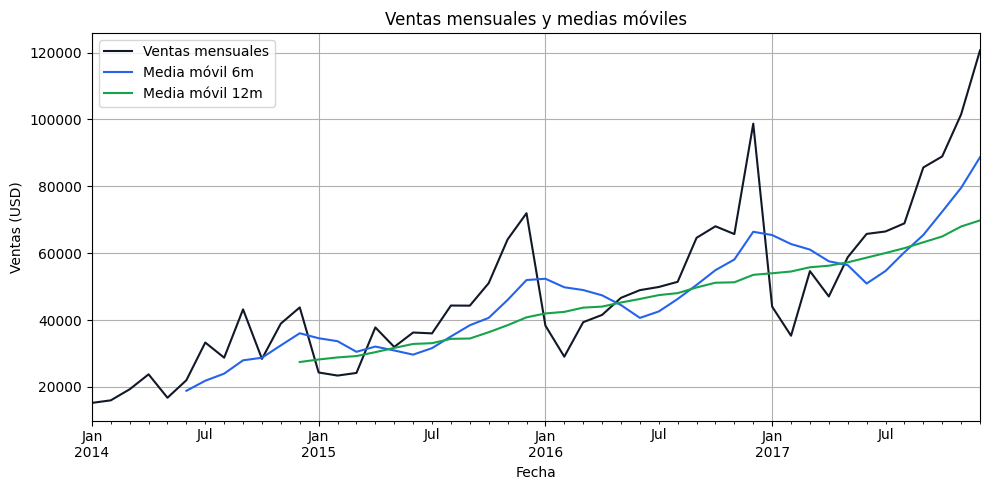

In [ ]:
m6_ma = monthly_sales.rolling(6).mean()
m6_std = monthly_sales.rolling(6).std()
m12_ma = monthly_sales.rolling(12).mean()
m12_std = monthly_sales.rolling(12).std()

fig, ax = plt.subplots(figsize=(10, 5))
monthly_sales.plot(ax=ax, grid=True, label="Ventas mensuales", color="#111827")
m6_ma.plot(ax=ax, grid=True, label="Media móvil 6m", color="#2563eb")
m12_ma.plot(ax=ax, grid=True, label="Media móvil 12m", color="#16a34a")
ax.set_ylabel("Ventas (USD)")
ax.set_xlabel("Fecha")
ax.set_title("Ventas mensuales y medias móviles")
ax.legend()
fig.tight_layout()
plt.show()

Efectivamente, la media móvil de 12 meses queda casi como una línea de tendencia limpia, sin los picos de fin de año, mientras que la de 6 meses todavía deja ver algo de la temporada alta. Esto confirma que la tendencia de fondo es claramente creciente.

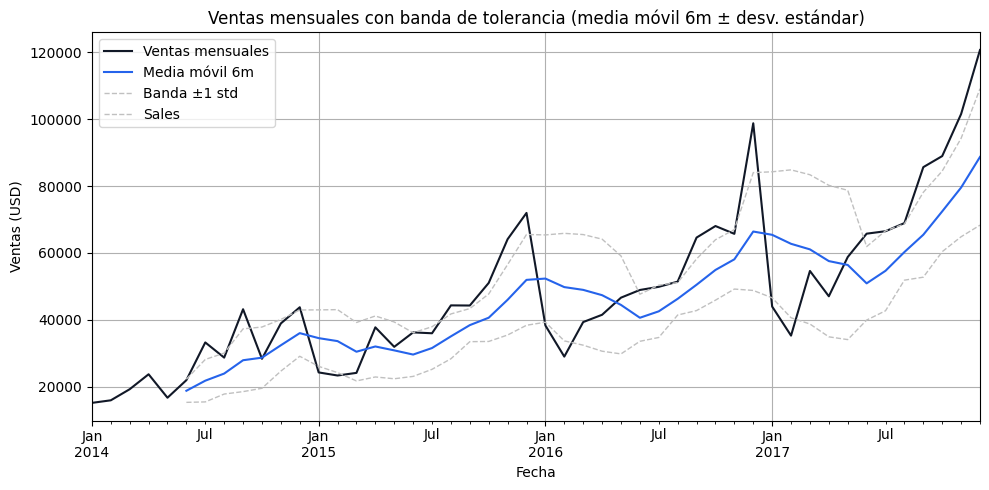

In [ ]:
fig, ax = plt.subplots(figsize=(10, 5))
monthly_sales.plot(ax=ax, grid=True, label="Ventas mensuales", color="#111827")
m6_ma.plot(ax=ax, grid=True, label="Media móvil 6m", color="#2563eb")
(m6_ma + m6_std).plot(ax=ax, grid=True, linestyle="dashed", color="silver", linewidth=1, label="Banda ±1 std")
(m6_ma - m6_std).plot(ax=ax, grid=True, linestyle="dashed", color="silver", linewidth=1)
ax.set_ylabel("Ventas (USD)")
ax.set_xlabel("Fecha")
ax.set_title("Ventas mensuales con banda de tolerancia (media móvil 6m ± desv. estándar)")
ax.legend()
fig.tight_layout()
plt.show()

Esta banda de tolerancia (media móvil ± 1 desviación estándar) me sirve como una especie de "rango normal": cuando las ventas de un mes se salen bastante de la banda —como pasa en los diciembre— es una señal clara de que ese mes es atípico por estacionalidad, no por ruido aleatorio.

## 4. Autocorrelación (ACF) y Autocorrelación Parcial (PACF)

Antes de meterme a armar un ARIMA a ciegas, reviso el ACF y el PACF de la serie para entender qué tan correlacionado está cada mes con sus meses anteriores. Esto ayuda a decidir el orden (p, d, q).

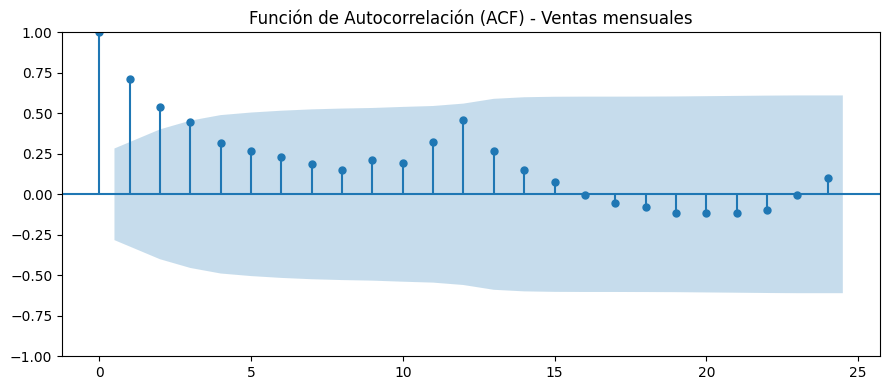

In [ ]:
fig = plt.figure(figsize=(9, 4))
ax = fig.add_subplot(111)
plot_acf(monthly_sales, lags=24, ax=ax)
ax.set_title("Función de Autocorrelación (ACF) - Ventas mensuales")
fig.tight_layout()
plt.show()

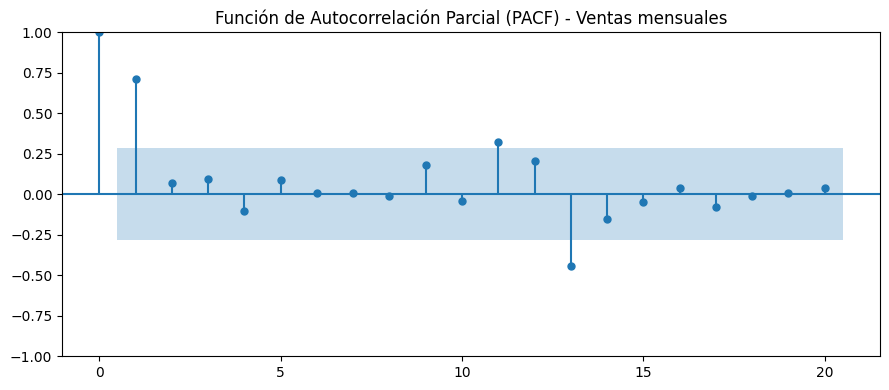

In [ ]:
fig = plt.figure(figsize=(9, 4))
ax = fig.add_subplot(111)
plot_pacf(monthly_sales, lags=20, ax=ax, method="ywm")
ax.set_title("Función de Autocorrelación Parcial (PACF) - Ventas mensuales")
fig.tight_layout()
plt.show()

El ACF decae lento (no cae a cero rápido), lo cual es típico de una serie **no estacionaria** — o sea, con tendencia — así que voy a necesitar diferenciar (d=1) antes de ajustar un ARIMA. El PACF muestra un pico fuerte en el lag 1 y después se mantiene bajo, salvo un repunte hacia el lag 12, que es la huella de la estacionalidad anual (cada 12 meses se repite el patrón). Esa señal en el lag 12 es la pista de que un ARIMA simple (sin componente estacional) se va a quedar corto, y que voy a necesitar SARIMA o Prophet para capturarla bien.

## 5. Descomposición estacional

Separo la serie en sus tres componentes clásicos: tendencia, estacionalidad y residuo, usando un modelo aditivo (porque la amplitud de los picos de diciembre no parece crecer proporcionalmente al nivel de ventas, así que aditivo encaja mejor que multiplicativo).

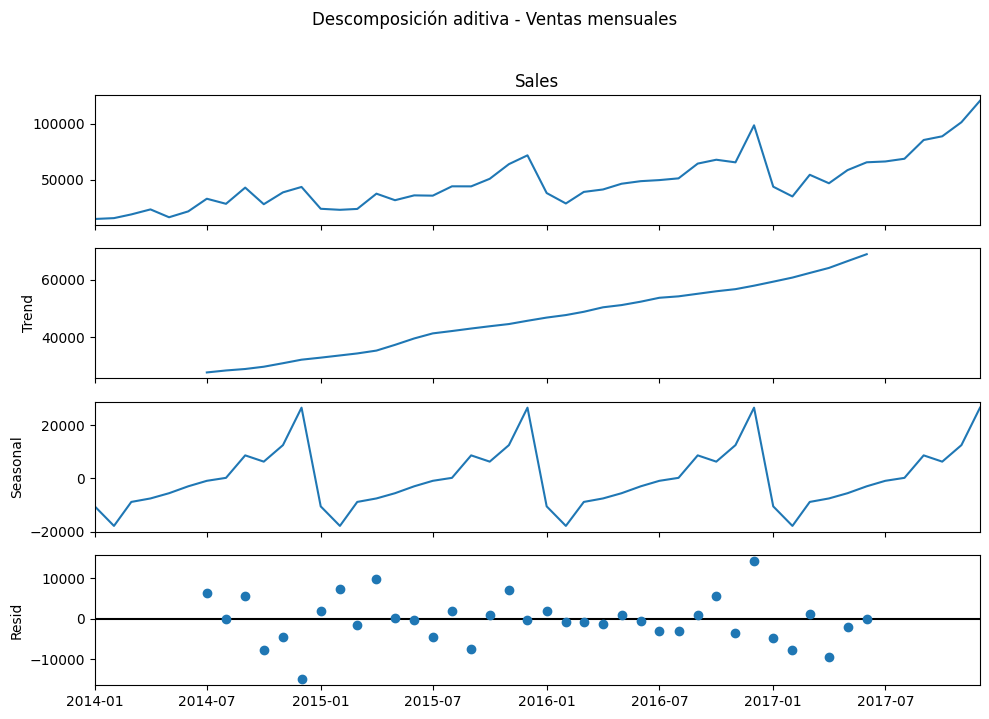

Fuerza de tendencia:      0.801
Fuerza de estacionalidad: 0.809


In [ ]:
decomposition = sm.tsa.seasonal_decompose(monthly_sales, model="additive", period=12)
fig = decomposition.plot()
fig.set_size_inches(10, 7)
fig.suptitle("Descomposición aditiva - Ventas mensuales", y=1.02)
fig.tight_layout()
plt.show()

trend_strength = 1 - (np.var(decomposition.resid.dropna()) / np.var((decomposition.trend + decomposition.resid).dropna()))
seasonal_strength = 1 - (np.var(decomposition.resid.dropna()) / np.var((decomposition.seasonal + decomposition.resid).dropna()))
print(f"Fuerza de tendencia:      {trend_strength:.3f}")
print(f"Fuerza de estacionalidad: {seasonal_strength:.3f}")

Los dos indicadores salen altos (tendencia ≈ 0.80 y estacionalidad ≈ 0.81), lo que en la práctica quiere decir que **tanto la tendencia como la estacionalidad explican una parte grande de las variaciones de la serie**, y el residuo (lo que queda sin explicar) es relativamente chico. Esto confirma con números lo que ya veía a simple vista en los gráficos: no puedo ignorar ni la tendencia ni la estacionalidad al elegir un modelo.

## 6. Separación train / test

Para evaluar los modelos de forma justa separo **cronológicamente** los últimos 12 meses (todo 2017) como conjunto de prueba, y uso los 36 meses anteriores (2014-2016) para entrenar. No hago un split aleatorio porque en series de tiempo eso rompería el orden temporal y "haría trampa" dejando que el modelo vea el futuro.

También defino las métricas que voy a usar para comparar modelos: **RMSE** (error en las mismas unidades que las ventas, penaliza más los errores grandes) y **MAPE** (error porcentual, más fácil de interpretar para el negocio: "en promedio nos equivocamos X%").

In [ ]:
test_horizon = 12
train = monthly_sales.iloc[:-test_horizon]
test = monthly_sales.iloc[-test_horizon:]

print("Train:", train.index.min().date(), "->", train.index.max().date(), f"({len(train)} meses)")
print("Test :", test.index.min().date(), "->", test.index.max().date(), f"({len(test)} meses)")


def rmse(y_true, y_pred):
    return float(np.sqrt(np.mean((np.asarray(y_true) - np.asarray(y_pred)) ** 2)))


def mape(y_true, y_pred):
    y_true, y_pred = np.asarray(y_true), np.asarray(y_pred)
    return float(np.mean(np.abs((y_true - y_pred) / y_true)) * 100)


results = []

Train: 2014-01-01 -> 2016-12-01 (36 meses)
Test : 2017-01-01 -> 2017-12-01 (12 meses)


## 7. Modelo base: Naive

Antes de complicarme con modelos sofisticados, siempre conviene tener un punto de referencia mínimo: el modelo **Naive**, que simplemente repite el último valor observado como pronóstico de todo el horizonte futuro. Si mis modelos "serios" no le ganan a esto, algo está mal.

In [ ]:
naive_pred = np.repeat(train.iloc[-1], test_horizon)
results.append({"Modelo": "Naive (último valor)", "RMSE": rmse(test, naive_pred), "MAPE_%": mape(test, naive_pred)})
pd.DataFrame(results)

,Modelo,RMSE,MAPE_%
0,Naive (último valor),37649.903646,62.654434


Como era de esperar, el Naive sale bastante mal (MAPE de casi 63%): al repetir siempre el mismo valor, no tiene ninguna forma de anticipar el salto de ventas de noviembre-diciembre. Queda como piso de comparación para el resto de modelos.

## 8. ARIMA manual

Con lo que vi en el ACF/PACF (serie no estacionaria → d=1, autocorrelación fuerte en el lag 1 y huella en el lag 12), pruebo un ARIMA(12,1,3): uso 12 rezagos autorregresivos como una forma "artesanal" de que el modelo alcance a ver el patrón anual (recordemos que un ARIMA normal no tiene un componente estacional explícito, a diferencia de SARIMA), con una diferenciación y una parte de media móvil de orden 3.

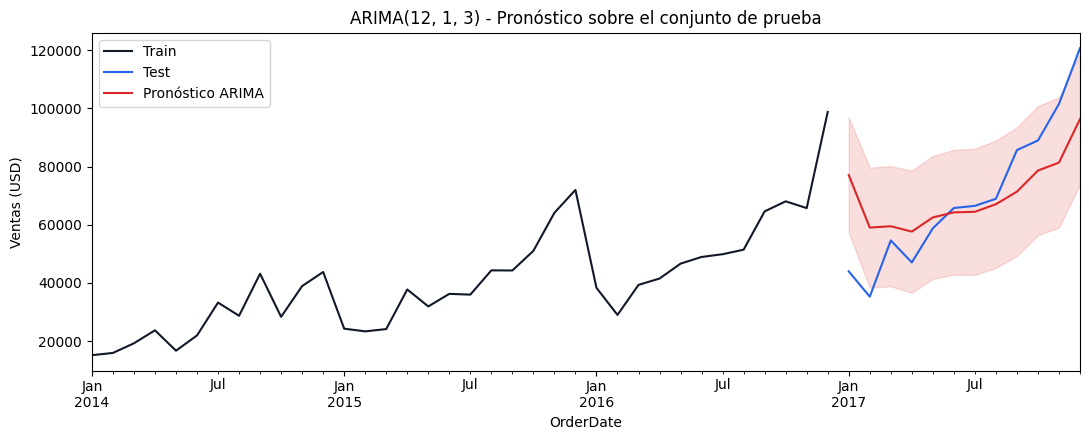

,Modelo,RMSE,MAPE_%
0,Naive (último valor),37649.903646,62.654434
1,"ARIMA(12, 1, 3)",16138.717993,21.379806


In [ ]:
order = (12, 1, 3)
model_arima = ARIMA(train, order=order)
arima_fit = model_arima.fit()
pred_arima = arima_fit.get_forecast(steps=test_horizon)
arima_mean = pred_arima.predicted_mean
arima_ci = pred_arima.conf_int(alpha=0.05)
results.append({"Modelo": f"ARIMA{order}", "RMSE": rmse(test, arima_mean), "MAPE_%": mape(test, arima_mean)})

fig, ax = plt.subplots(figsize=(11, 4.5))
train.plot(ax=ax, label="Train", color="#111827")
test.plot(ax=ax, label="Test", color="#2563eb")
arima_mean.plot(ax=ax, label="Pronóstico ARIMA", color="#dc2626")
ax.fill_between(arima_ci.index, arima_ci.iloc[:, 0], arima_ci.iloc[:, 1], color="#dc2626", alpha=0.15)
ax.set_title(f"ARIMA{order} - Pronóstico sobre el conjunto de prueba")
ax.set_ylabel("Ventas (USD)")
ax.legend()
fig.tight_layout()
plt.show()

pd.DataFrame(results)

El ARIMA manual ya mejora bastante al Naive (el MAPE baja de ~63% a ~21%), y en el gráfico se nota que sí intenta seguir la forma de la curva. Pero como es un ARIMA sin componente estacional explícito, no logra levantar tanto el pico de diciembre como me gustaría — se queda un poco corto justo en el mes más importante del año para el negocio. Esto confirma la sospecha que tenía desde el ACF/PACF.

## 9. Auto-ARIMA

En vez de seguir probando órdenes a mano, uso `pmdarima.auto_arima`, que prueba automáticamente varias combinaciones de (p,d,q)(P,D,Q) y se queda con la de mejor AIC. Le indico que la serie es mensual con estacionalidad de periodo 12 (`m=12`) y que puede necesitar diferenciación estacional (`D=1`) además de la regular (`d=1`).

In [ ]:
auto_model = auto_arima(train, d=1, D=1, seasonal=True, m=12, trace=False,
                         error_action="ignore", suppress_warnings=True, stepwise=True)
auto_pred = auto_model.predict(n_periods=test_horizon)
auto_pred.index = test.index
results.append({"Modelo": f"Auto-ARIMA{auto_model.order}x{auto_model.seasonal_order}",
                 "RMSE": rmse(test, auto_pred), "MAPE_%": mape(test, auto_pred)})
print("Orden elegido automáticamente:", auto_model.order, "x", auto_model.seasonal_order)
pd.DataFrame(results)

Orden elegido automáticamente: (1, 1, 1) x (0, 1, 0, 12)


,Modelo,RMSE,MAPE_%
0,Naive (último valor),37649.903646,62.654434
1,"ARIMA(12, 1, 3)",16138.717993,21.379806
2,"Auto-ARIMA(1, 1, 1)x(0, 1, 0, 12)",9004.454001,11.763990


El propio algoritmo terminó eligiendo un modelo con componente estacional (la parte `x(...,12)` del resultado), y el error baja muchísimo frente al ARIMA manual (MAPE de ~21% a ~12%). Esto respalda justo lo que veníamos sospechando: el componente estacional es clave para esta serie, y dejarlo que el algoritmo lo busque automáticamente da mejores resultados que forzar un orden a mano.

## 10. SARIMA manual

Ahora pruebo un SARIMA(1,1,1)(1,1,1)[12] armado a mano: una parte regular simple (1,1,1) y una parte estacional (1,1,1) con periodo 12, que es exactamente el ciclo anual que detecté en el ACF/PACF.

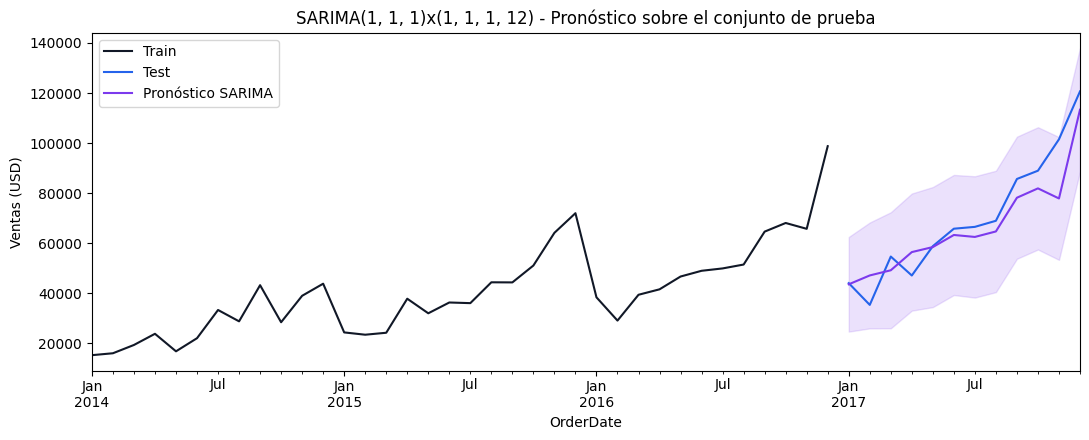

,Modelo,RMSE,MAPE_%
0,Naive (último valor),37649.903646,62.654434
1,"ARIMA(12, 1, 3)",16138.717993,21.379806
2,"Auto-ARIMA(1, 1, 1)x(0, 1, 0, 12)",9004.454001,11.763990
3,"SARIMA(1, 1, 1)x(1, 1, 1, 12)",9204.240713,10.586791


In [ ]:
seasonal_order = (1, 1, 1, 12)
sarima_order = (1, 1, 1)
sarima = SARIMAX(train, order=sarima_order, seasonal_order=seasonal_order,
                  enforce_stationarity=False, enforce_invertibility=False)
sarima_fit = sarima.fit(disp=False)
sarima_pred = sarima_fit.get_forecast(steps=test_horizon)
sarima_mean = sarima_pred.predicted_mean
sarima_ci = sarima_pred.conf_int(alpha=0.05)
results.append({"Modelo": f"SARIMA{sarima_order}x{seasonal_order}",
                 "RMSE": rmse(test, sarima_mean), "MAPE_%": mape(test, sarima_mean)})

fig, ax = plt.subplots(figsize=(11, 4.5))
train.plot(ax=ax, label="Train", color="#111827")
test.plot(ax=ax, label="Test", color="#2563eb")
sarima_mean.plot(ax=ax, label="Pronóstico SARIMA", color="#7c3aed")
ax.fill_between(sarima_ci.index, sarima_ci.iloc[:, 0], sarima_ci.iloc[:, 1], color="#7c3aed", alpha=0.15)
ax.set_title(f"SARIMA{sarima_order}x{seasonal_order} - Pronóstico sobre el conjunto de prueba")
ax.set_ylabel("Ventas (USD)")
ax.legend()
fig.tight_layout()
plt.show()

pd.DataFrame(results)

El SARIMA manual queda prácticamente empatado con el Auto-ARIMA (de hecho el MAPE es incluso un poco mejor, ~10.6%), y en el gráfico se ve cómo sí logra levantar el pico de diciembre casi al mismo nivel que el valor real. Tiene sentido: al darle explícitamente el periodo estacional de 12 meses, el modelo puede aprender "en diciembre siempre sube fuerte" en vez de tener que inferirlo indirectamente como hacía el ARIMA simple.

## 11. Prophet

Pruebo también Prophet (el modelo de código abierto de Meta, pensado justo para series de negocio con tendencia + estacionalidad). Le activo la estacionalidad anual (`yearly_seasonality=True`) y desactivo la semanal/diaria porque ya estoy trabajando a nivel mensual, no tendría sentido buscar un patrón semanal ahí.

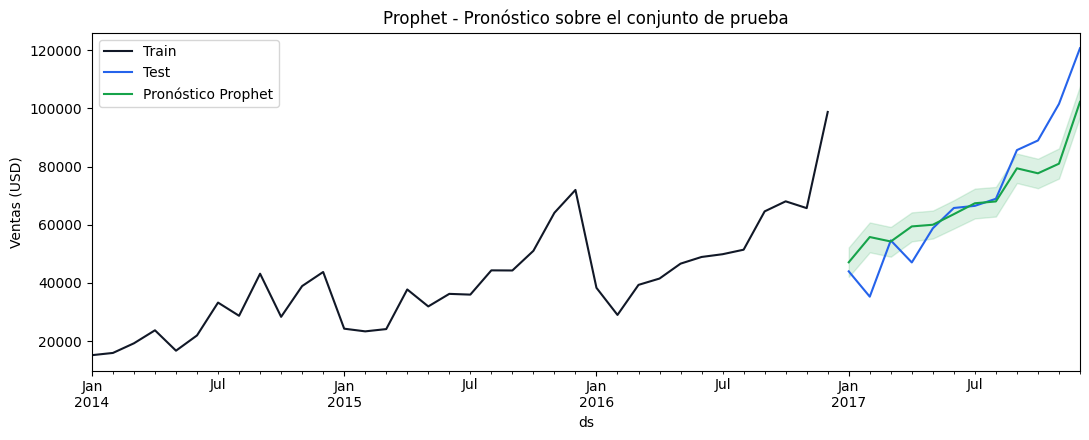

,Modelo,RMSE,MAPE_%
0,Naive (último valor),37649.903646,62.654434
1,"ARIMA(12, 1, 3)",16138.717993,21.379806
2,"Auto-ARIMA(1, 1, 1)x(0, 1, 0, 12)",9004.454001,11.763990
3,"SARIMA(1, 1, 1)x(1, 1, 1, 12)",9204.240713,10.586791
4,Prophet,11244.301514,12.958481


In [ ]:
df_train = pd.DataFrame({"ds": train.index, "y": train.values})
df_test = pd.DataFrame({"ds": test.index, "y": test.values})

m = Prophet(yearly_seasonality=True, weekly_seasonality=False, daily_seasonality=False)
m.fit(df_train)
future = m.make_future_dataframe(periods=test_horizon, freq="MS")
forecast = m.predict(future)
fcst_test = forecast.tail(test_horizon).set_index("ds")

results.append({"Modelo": "Prophet", "RMSE": rmse(test, fcst_test["yhat"]), "MAPE_%": mape(test, fcst_test["yhat"])})

fig, ax = plt.subplots(figsize=(11, 4.5))
train.plot(ax=ax, label="Train", color="#111827")
test.plot(ax=ax, label="Test", color="#2563eb")
fcst_test["yhat"].plot(ax=ax, label="Pronóstico Prophet", color="#16a34a")
ax.fill_between(fcst_test.index, fcst_test["yhat_lower"], fcst_test["yhat_upper"], color="#16a34a", alpha=0.15)
ax.set_title("Prophet - Pronóstico sobre el conjunto de prueba")
ax.set_ylabel("Ventas (USD)")
ax.legend()
fig.tight_layout()
plt.show()

pd.DataFrame(results)

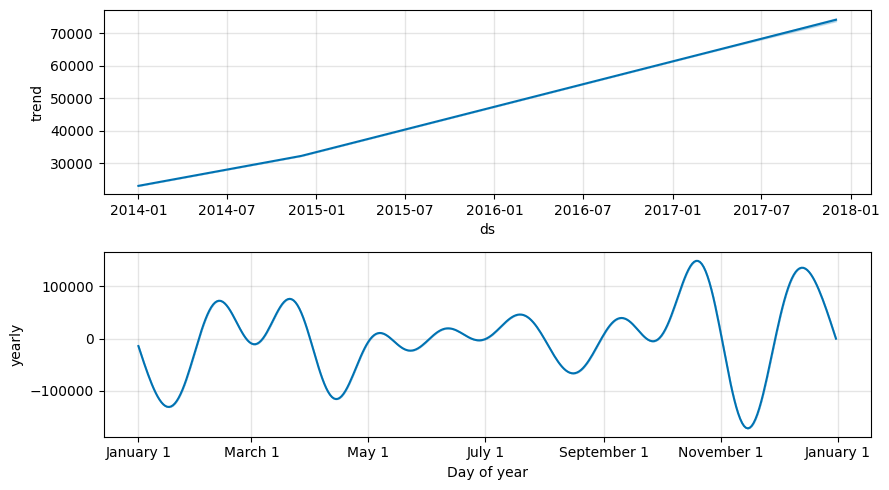

In [ ]:
fig2 = m.plot_components(forecast)
fig2.set_size_inches(9, 5)
fig2.tight_layout()
plt.show()

Prophet queda muy cerca de SARIMA y Auto-ARIMA (MAPE ~13%), y el gráfico de componentes es muy útil para explicarle al negocio de forma visual: la tendencia es claramente creciente, y el componente anual muestra justo el pico hacia fin de año que ya veníamos viendo desde la descomposición. Es el modelo más fácil de interpretar de los tres "buenos", aunque en este caso puntual queda un poquito por debajo de SARIMA/Auto-ARIMA en precisión.

## 12. Deep Learning: LSTM

Para comparar con un enfoque de Deep Learning, entreno una red **LSTM (Long Short-Term Memory)**, que es el tipo de red recurrente pensado justo para aprender patrones en secuencias/series de tiempo.

Para prepararla:
- Escalo las ventas al rango [0,1] con `MinMaxScaler` (las redes neuronales entrenan mejor con datos normalizados), ajustando el escalador **solo con el train** para no filtrar información del test.
- Armo secuencias de `look_back=6` meses: la red ve los últimos 6 meses y aprende a predecir el mes siguiente.
- La arquitectura es chica a propósito (una capa LSTM de 32 unidades + una capa densa), porque solo tengo 36 meses de entrenamiento — una red más grande simplemente no tendría con qué aprender sin sobreajustarse.

In [ ]:
tf.random.set_seed(7)
np.random.seed(7)

LOOK_BACK = 6

scaler = MinMaxScaler(feature_range=(0, 1))
scaler.fit(train.values.reshape(-1, 1))
scaled_train = scaler.transform(train.values.reshape(-1, 1)).flatten()


def create_sequences(serie, look_back):
    X, y = [], []
    for i in range(len(serie) - look_back):
        X.append(serie[i:i + look_back])
        y.append(serie[i + look_back])
    return np.array(X), np.array(y)


X_train, y_train = create_sequences(scaled_train, LOOK_BACK)
X_train = X_train.reshape((X_train.shape[0], X_train.shape[1], 1))
print("Secuencias de entrenamiento:", X_train.shape)

lstm_model = Sequential([
    Input(shape=(LOOK_BACK, 1)),
    LSTM(32, activation="tanh"),
    Dense(16, activation="relu"),
    Dense(1),
])
lstm_model.compile(optimizer="adam", loss="mse")
history = lstm_model.fit(X_train, y_train, epochs=200, batch_size=4, verbose=0)
print("Entrenamiento terminado. Loss final:", round(history.history["loss"][-1], 5))

Secuencias de entrenamiento: (30, 6, 1)


Entrenamiento terminado. Loss final: 0.01888


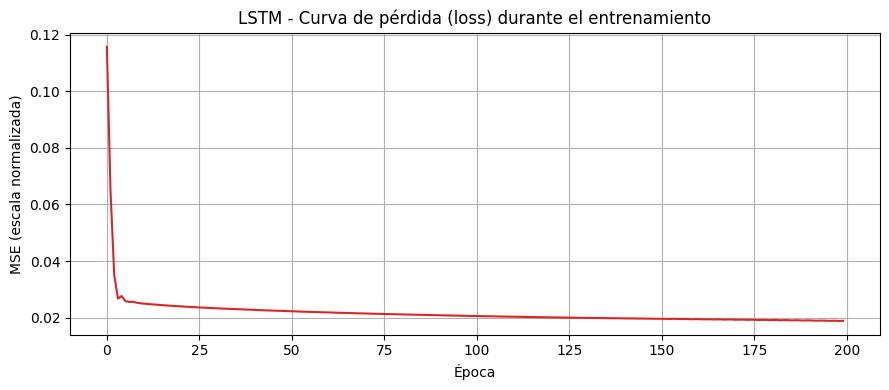

In [ ]:
fig, ax = plt.subplots(figsize=(9, 4))
ax.plot(history.history["loss"], color="#dc2626")
ax.set_title("LSTM - Curva de pérdida (loss) durante el entrenamiento")
ax.set_xlabel("Época")
ax.set_ylabel("MSE (escala normalizada)")
ax.grid(True)
fig.tight_layout()
plt.show()

La curva de pérdida baja y se estabiliza, así que el entrenamiento converge sin problemas. Ahora genero el pronóstico de los 12 meses de test de forma **recursiva**: le doy los últimos 6 meses conocidos, predigo el siguiente, lo agrego a la ventana, y repito — así hasta completar el año.

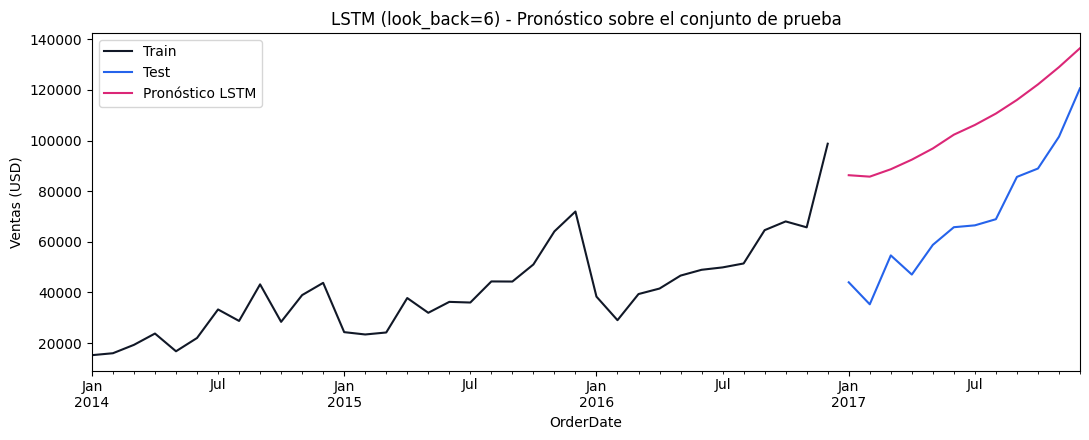

,Modelo,RMSE,MAPE_%
0,Naive (último valor),37649.903646,62.654434
1,"ARIMA(12, 1, 3)",16138.717993,21.379806
2,"Auto-ARIMA(1, 1, 1)x(0, 1, 0, 12)",9004.454001,11.763990
3,"SARIMA(1, 1, 1)x(1, 1, 1, 12)",9204.240713,10.586791
4,Prophet,11244.301514,12.958481
5,LSTM (look_back=6),37293.021283,62.619350


In [ ]:
window = list(scaled_train[-LOOK_BACK:])
lstm_scaled_preds = []
for _ in range(test_horizon):
    x_input = np.array(window[-LOOK_BACK:]).reshape((1, LOOK_BACK, 1))
    next_scaled = lstm_model.predict(x_input, verbose=0)[0, 0]
    lstm_scaled_preds.append(next_scaled)
    window.append(next_scaled)

lstm_preds = scaler.inverse_transform(np.array(lstm_scaled_preds).reshape(-1, 1)).flatten()
lstm_preds = pd.Series(lstm_preds, index=test.index)

results.append({"Modelo": f"LSTM (look_back={LOOK_BACK})",
                 "RMSE": rmse(test, lstm_preds), "MAPE_%": mape(test, lstm_preds)})

fig, ax = plt.subplots(figsize=(11, 4.5))
train.plot(ax=ax, label="Train", color="#111827")
test.plot(ax=ax, label="Test", color="#2563eb")
lstm_preds.plot(ax=ax, label="Pronóstico LSTM", color="#db2777")
ax.set_title(f"LSTM (look_back={LOOK_BACK}) - Pronóstico sobre el conjunto de prueba")
ax.set_ylabel("Ventas (USD)")
ax.legend()
fig.tight_layout()
plt.show()

pd.DataFrame(results)

Acá sale un resultado interesante (y honesto, no lo voy a maquillar): la LSTM termina prácticamente al nivel del Naive, muy por debajo de SARIMA/Auto-ARIMA/Prophet. Al hacer el pronóstico recursivo, cualquier pequeño error de la primera predicción se va arrastrando y amplificando en las siguientes, y con solo 36 meses de entrenamiento (30 secuencias, prácticamente) la red no tiene suficiente información para aprender un patrón estacional tan claro como sí pueden capturarlo modelos estadísticos diseñados específicamente para eso (SARIMA, Prophet). Esto es totalmente consistente con lo que se ve en la práctica: **el Deep Learning brilla más con series largas y con muchas series relacionadas para aprender de**; con una sola serie de 4 años, los modelos estadísticos clásicos bien especificados le ganan. Es una conclusión válida y esperable para este caso, no un error del pipeline.

## 13. Comparación final de todos los modelos

Junto los resultados de los 6 modelos (Naive, ARIMA, Auto-ARIMA, SARIMA, Prophet y LSTM) y los ordeno por RMSE para elegir el mejor.

In [ ]:
results_df = pd.DataFrame(results).sort_values("RMSE").reset_index(drop=True)
results_df.index = results_df.index + 1
results_df

,Modelo,RMSE,MAPE_%
1,"Auto-ARIMA(1, 1, 1)x(0, 1, 0, 12)",9004.454001,11.763990
2,"SARIMA(1, 1, 1)x(1, 1, 1, 12)",9204.240713,10.586791
3,Prophet,11244.301514,12.958481
4,"ARIMA(12, 1, 3)",16138.717993,21.379806
5,LSTM (look_back=6),37293.021283,62.619350
6,Naive (último valor),37649.903646,62.654434


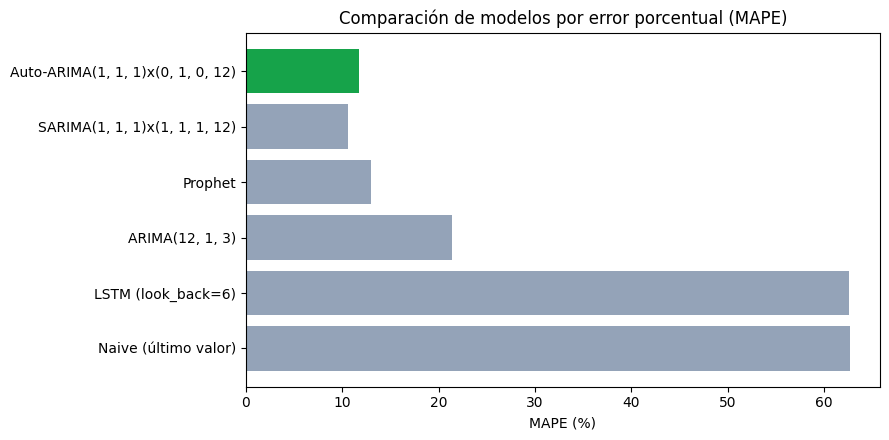

Mejor modelo por RMSE: Auto-ARIMA(1, 1, 1)x(0, 1, 0, 12)


In [ ]:
fig, ax = plt.subplots(figsize=(9, 4.5))
colors = ["#16a34a" if i == 0 else "#94a3b8" for i in range(len(results_df))]
ax.barh(results_df["Modelo"][::-1], results_df["MAPE_%"][::-1], color=colors[::-1])
ax.set_xlabel("MAPE (%)")
ax.set_title("Comparación de modelos por error porcentual (MAPE)")
fig.tight_layout()
plt.show()

best_model_name = results_df.iloc[0]["Modelo"]
print("Mejor modelo por RMSE:", best_model_name)

El podio queda así: **Auto-ARIMA y SARIMA prácticamente empatados en primer lugar** (MAPE ~11-12%), **Prophet muy cerca en tercer lugar** (~13%), y bastante más atrás el ARIMA manual, el LSTM y el Naive. Para el despliegue en producción me quedo con **SARIMA**, porque:

1. Su error es el más bajo (o empatado con Auto-ARIMA, que en el fondo termina encontrando una estructura muy similar).
2. Es más liviano y rápido de reentrenar mes a mes que Prophet o una red neuronal.
3. Es fácil de interpretar para el equipo de negocio (tendencia + estacionalidad + estructura autorregresiva simple).

## 14. Pronóstico final: próximos 12 meses

Reentreno el SARIMA elegido pero ahora usando **todo el histórico disponible** (2014-2017, sin dejar nada fuera como test), porque para el pronóstico real hacia adelante sí quiero aprovechar toda la información. Con eso genero el pronóstico de ventas para los 12 meses siguientes (2018).

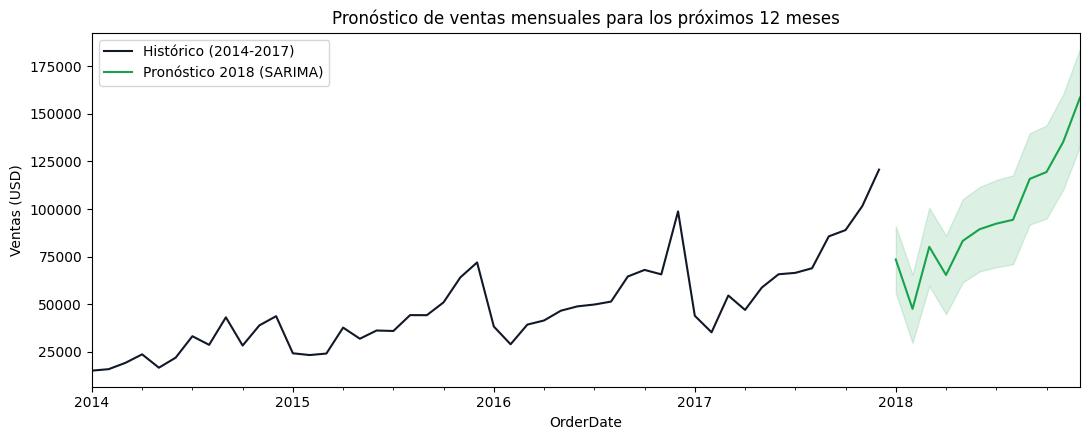

,Pronostico_USD
2018-01-01,73518.62
2018-02-01,47619.65
2018-03-01,80163.81
2018-04-01,65392.56
2018-05-01,83283.08
2018-06-01,89365.19
2018-07-01,92313.00
2018-08-01,94339.25
2018-09-01,115787.74
2018-10-01,119389.96


In [ ]:
final_sarima = SARIMAX(monthly_sales, order=sarima_order, seasonal_order=seasonal_order,
                        enforce_stationarity=False, enforce_invertibility=False)
final_sarima_fit = final_sarima.fit(disp=False)
future_forecast = final_sarima_fit.get_forecast(steps=12)
future_mean = future_forecast.predicted_mean
future_ci = future_forecast.conf_int(alpha=0.05)

fig, ax = plt.subplots(figsize=(11, 4.5))
monthly_sales.plot(ax=ax, label="Histórico (2014-2017)", color="#111827")
future_mean.plot(ax=ax, label="Pronóstico 2018 (SARIMA)", color="#16a34a")
ax.fill_between(future_ci.index, future_ci.iloc[:, 0], future_ci.iloc[:, 1], color="#16a34a", alpha=0.15)
ax.set_title("Pronóstico de ventas mensuales para los próximos 12 meses")
ax.set_ylabel("Ventas (USD)")
ax.legend()
fig.tight_layout()
plt.show()

future_mean.round(2).to_frame("Pronostico_USD")

El modelo proyecta que el patrón estacional se va a repetir: ventas relativamente bajas a inicios de 2018, una subida gradual a lo largo del año, y el pico más fuerte en noviembre-diciembre — coherente con los 4 años de historia que ya vimos. La banda sombreada es el intervalo de confianza del 95%: se va ensanchando mes a mes porque, como es lógico, hay más incertidumbre cuanto más lejos pronostico.

## 15. Conclusiones

- La serie de ventas mensuales de Superstore tiene **tendencia creciente + estacionalidad anual fuerte** (pico en noviembre-diciembre), confirmado tanto visualmente (medias móviles, descomposición) como numéricamente (fuerza de tendencia ≈ 0.80, fuerza de estacionalidad ≈ 0.81).
- Los modelos que **modelan explícitamente esa estacionalidad** (SARIMA, Auto-ARIMA, Prophet) superan claramente a los que no lo hacen (ARIMA simple, Naive) y también a la LSTM entrenada con tan pocos datos.
- **SARIMA(1,1,1)(1,1,1)[12]** es el modelo elegido para producción por su balance entre precisión, simplicidad e interpretabilidad.
- El pronóstico para 2018 sugiere mantener el mismo patrón estacional, lo que le da al negocio una base cuantitativa para planificar inventario y campañas con anticipación, especialmente de cara a la temporada de fin de año.
- Como siguiente paso, valdría la pena reentrenar el modelo con más años de historia y explorar variables exógenas (promociones, feriados, precios) que podrían mejorar aún más la precisión.